# Enclosing-circle diameter: pixel centres, +1 pixel, pixel corners

The maximum dimension of an optical-array-probe image is often taken as the diameter of the
smallest circle that encloses its shadowed pixels. A pixel is a square, not a point, so the
circle can be drawn around three different things, and each gives a different size for the
same image:

| Convention | Diameter | Single pixel |
|---|---|---|
| **Pixel centres** | `2 r`, r = smallest circle through the pixel centres | 0 px |
| **+1 pixel** (this package's engine; NCAR's Process2D writes it as Miniball radius + 0.5 px) | `2 r + 1` | 1 px |
| **Pixel corners** | `2 R`, R = smallest circle through every corner of every pixel | 1.41 px |

The engine's minimum enclosing circle, `arrayprobe_uiops.min_circle.cgal_min_r_v35`, is a port of
the UIOOPS C++ routine and returns `1 + 2 r` over the pixel centres. The other two conventions are
derived from the same call below, so all three use one exact circle solver.

The difference is a fixed offset in pixels, so it matters most for the smallest particles: at
10 µm pixels, +0.5 px on the radius is +10 µm on every diameter. This notebook measures the
offsets on synthetic discs of known diameter, needles and aggregates (fixed seed), and what the
offset does to a size distribution, in dB per bin.

**Before this:** [01_start_here](../1_getting_started/01_start_here.ipynb) (Start here: process one probe file and look at what came out). **Related:** [04_size_definition_sensitivity](../6_science/04_size_definition_sensitivity.ipynb). **Needs:** `pip install "arrayprobe[extra]"` (matplotlib).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/4_methods_and_literature/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

This cell defines the three ways of measuring the diameter of the same image: a circle through the pixel centres, the engine's value (centres plus one pixel), and a circle through the pixel corners. It then applies them to a single pixel, where the three should give 0, 1 and 1.41 pixels.

In [2]:
import numpy as np
from arrayprobe_uiops.min_circle import cgal_min_r_v35

PIX_UM = 10.0  # pixel size, µm


def d_engine(img):
    """Engine diameter in pixels (+1 pixel convention). Rows are diodes, columns slices."""
    return cgal_min_r_v35(img, 1.0)[0]


def d_centres(img):
    """Smallest circle through the pixel centres: the engine value minus its +1."""
    return d_engine(img) - 1.0


def d_corners(img):
    """Smallest circle through every pixel corner. Corners sit at half-integer positions, so
    they are laid on a grid of twice the resolution and passed to the same solver."""
    rows, cols = np.nonzero(img)
    big = np.zeros((2 * img.shape[0] + 1, 2 * img.shape[1] + 1), dtype=bool)
    for dr in (0, 2):
        for dc in (0, 2):
            big[2 * rows + dr, 2 * cols + dc] = True
    return (d_engine(big) - 1.0) / 2.0  # 2R on the doubled grid, halved


one = np.ones((1, 1), dtype=bool)
print(f"single pixel: centres {d_centres(one):.2f}, engine {d_engine(one):.2f}, "
      f"corners {d_corners(one):.2f} px")


single pixel: centres 0.00, engine 1.00, corners 1.41 px


## The three circles on one image

Before any numbers, the figure below draws the three circles on one small synthetic particle at
10 µm pixels. Every diameter in the legend comes from the functions above, and each circle is
centred where the engine's solver puts it.


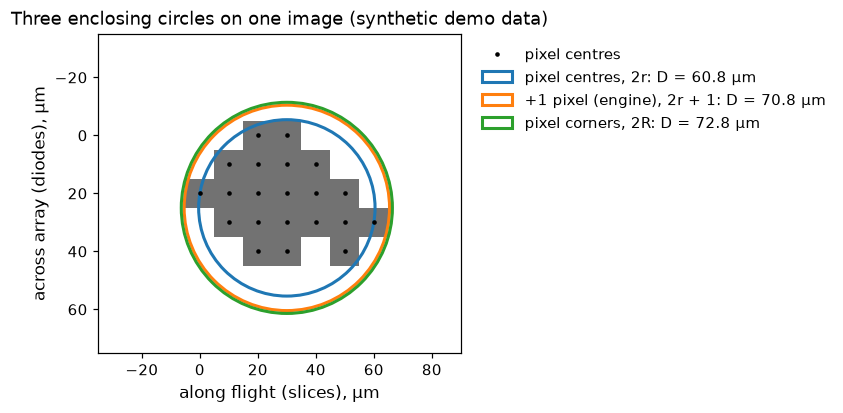

In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

demo = np.array([[0, 0, 1, 1, 0, 0, 0],
                 [0, 1, 1, 1, 1, 0, 0],
                 [1, 1, 1, 1, 1, 1, 0],
                 [0, 1, 1, 1, 1, 1, 1],
                 [0, 0, 1, 1, 0, 1, 0]], dtype=bool)
rows, cols = np.nonzero(demo)
_, cy, cx = cgal_min_r_v35(demo, 1.0)                    # centre, 0-based (row, column)
big = np.zeros((2 * demo.shape[0] + 1, 2 * demo.shape[1] + 1), dtype=bool)
for dr in (0, 2):
    for dc in (0, 2):
        big[2 * rows + dr, 2 * cols + dc] = True
_, by, bx = cgal_min_r_v35(big, 1.0)
ky, kx = by / 2 - 0.5, bx / 2 - 0.5                     # corner circle's centre, pixel units

fig, ax = plt.subplots(figsize=(7, 5.5))
ny, nx = demo.shape
ax.imshow(demo, cmap="Greys", vmin=0, vmax=1.6, origin="upper",
          extent=(-0.5 * PIX_UM, (nx - 0.5) * PIX_UM, (ny - 0.5) * PIX_UM, -0.5 * PIX_UM))
ax.plot(cols * PIX_UM, rows * PIX_UM, "k.", ms=4, label="pixel centres")
for (yc, xc), d_px, colour, name in [
        ((cy, cx), d_centres(demo), "tab:blue", "pixel centres, 2r"),
        ((cy, cx), d_engine(demo), "tab:orange", "+1 pixel (engine), 2r + 1"),
        ((ky, kx), d_corners(demo), "tab:green", "pixel corners, 2R")]:
    ax.add_patch(Circle((xc * PIX_UM, yc * PIX_UM), d_px * PIX_UM / 2, fill=False, lw=2,
                        color=colour, label=f"{name}: D = {d_px * PIX_UM:.1f} µm"))
ax.set_xlim(-6 * PIX_UM / 2 - 5, (nx + 2) * PIX_UM)
ax.set_ylim((ny + 2.5) * PIX_UM, -3.5 * PIX_UM)
ax.set_aspect("equal")
ax.set_xlabel("along flight (slices), µm", fontsize=11)
ax.set_ylabel("across array (diodes), µm", fontsize=11)
ax.set_title("Three enclosing circles on one image (synthetic demo data)", fontsize=12)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), fontsize=10, frameon=False)
ax.tick_params(labelsize=10)
fig.tight_layout()
plt.show()


*Figure 1.* A 21-pixel synthetic particle at 10 µm pixels (grey squares; dots mark pixel
centres) with its three enclosing circles. Blue passes through the outermost pixel centres; orange
is the engine's value, the same circle widened by half a pixel on the radius; green encloses every
pixel corner and has its own centre. The legend gives each diameter: orange is always exactly one pixel
wider than blue, and green is wider still by an amount that depends on the particle's shape.


## Discs of known diameter

Each disc is drawn with a random sub-pixel centre (fixed seed); a pixel is shadowed when its
centre lies inside the disc, the usual rule for an ideal shadow at a 50 % threshold. Twenty
placements per diameter; the table gives the mean bias of each convention against the true
diameter, in pixels and percent.


In [4]:
rng = np.random.default_rng(20261005)


def disc(d_px, rng):
    n = int(np.ceil(d_px)) + 4
    cy, cx = n / 2 + rng.uniform(-0.5, 0.5, 2)
    yy, xx = np.mgrid[0:n, 0:n]
    return (yy - cy) ** 2 + (xx - cx) ** 2 <= (d_px / 2) ** 2


true_d = np.array([2, 3, 5, 10, 20, 50, 100], dtype=float)
means = np.array([
    np.mean([[f(img) for f in (d_centres, d_engine, d_corners)]
             for img in (disc(d, rng) for _ in range(20))], axis=0)
    for d in true_d
])

print(f"{'true D px':>9} {'µm':>5} | {'bias px: centres':>16} {'engine':>7} {'corners':>8} |"
      f" {'bias %: centres':>15} {'engine':>7} {'corners':>8}")
for d, r in zip(true_d, means):
    b = r - d
    print(f"{d:9.0f} {d * PIX_UM:5.0f} | {b[0]:16.2f} {b[1]:7.2f} {b[2]:8.2f} |"
          f" {100 * b[0] / d:15.1f} {100 * b[1] / d:7.1f} {100 * b[2] / d:8.1f}")


true D px    µm | bias px: centres  engine  corners | bias %: centres  engine  corners
        2    20 |            -0.63    0.37     0.77 |           -31.4    18.6     38.5
        3    30 |            -0.46    0.54     0.88 |           -15.2    18.1     29.4
        5    50 |            -0.40    0.60     0.93 |            -8.0    12.0     18.7
       10   100 |            -0.18    0.82     1.14 |            -1.8     8.2     11.4
       20   200 |            -0.08    0.92     1.25 |            -0.4     4.6      6.2
       50   500 |            -0.03    0.97     1.33 |            -0.1     1.9      2.7
      100  1000 |            -0.02    0.98     1.34 |            -0.0     1.0      1.3


Under a centre-in shadow rule the pixel-centre circle is the one that converges on the true
diameter: its bias shrinks from about -0.6 px at 2 pixels to -0.02 px at 100, because the
outermost shadowed centres approach the true edge as the disc grows. The +1 pixel convention
therefore reads high by up to one pixel (+0.37 px at 2 pixels, +0.98 px at 100), and the
pixel-corner circle by up to about 1.3 px. In percent the offsets fall roughly as 1/D: at
20-50 µm (2-5 pixels at 10 µm) the engine's convention reads 12-19 % large, at 1 mm about 1 %.
Which convention is "right" depends on how the probe's shadow threshold maps a particle onto
pixels; the offset between conventions does not.


## Needles and aggregates

A one-pixel-wide needle of length L shows the geometry plainly: centres give L - 1, the engine
gives L, corners give sqrt(L² + 1). Aggregates (three to six overlapping discs of random sizes
and offsets, fixed seed) have no single true diameter, so the conventions are compared with
each other.


In [5]:
print(f"{'needle L':>8} | {'centres':>8} {'engine':>7} {'corners':>8}")
for L in (2, 5, 10, 30, 100):
    img = np.ones((1, L), dtype=bool)
    print(f"{L:8d} | {d_centres(img):8.2f} {d_engine(img):7.2f} {d_corners(img):8.2f}")


def aggregate(rng):
    n = 64
    yy, xx = np.mgrid[0:n, 0:n]
    img = np.zeros((n, n), dtype=bool)
    cy = cx = n / 2
    for _ in range(rng.integers(3, 7)):
        r = rng.uniform(1.5, 6)
        img |= (yy - cy) ** 2 + (xx - cx) ** 2 <= r * r
        ang = rng.uniform(0, 2 * np.pi)
        cy, cx = cy + 1.6 * r * np.sin(ang), cx + 1.6 * r * np.cos(ang)
    return img


agg = np.array([[f(img) for f in (d_centres, d_engine, d_corners)]
                for img in (aggregate(rng) for _ in range(40))])
diff = agg[:, 2] - agg[:, 1]
print()
print(f"aggregates (40): engine D {agg[:, 1].min():.1f}-{agg[:, 1].max():.1f} px")
print(f"  engine - centres = {np.mean(agg[:, 1] - agg[:, 0]):.2f} px (exactly 1 by construction)")
print(f"  corners - engine = {diff.mean():+.2f} px (range {diff.min():+.2f} to {diff.max():+.2f})")


needle L |  centres  engine  corners
       2 |     1.00    2.00     2.24
       5 |     4.00    5.00     5.10
      10 |     9.00   10.00    10.05
      30 |    29.00   30.00    30.02
     100 |    99.00  100.00   100.00

aggregates (40): engine D 11.3-39.9 px
  engine - centres = 1.00 px (exactly 1 by construction)
  corners - engine = +0.31 px (range +0.13 to +0.41)


## What a +0.5 px radius does to a size distribution

A population is drawn from an exponential size distribution (fixed seed), sized to whole
pixels under the pixel-centre convention, then again with +0.5 px on the radius (+1 px, 10 µm,
on the diameter), and binned on the same bins. Each bin's change is in dB,
`10 log10(N_plus1 / N_centres)`. A one-pixel shift moves particles up across bin edges, so a
falling distribution gains counts in each bin, most where one pixel is a large fraction of the
bin width.


In [6]:
d_true_um = rng.exponential(80.0, 200_000) + 15.0
d_c_um = PIX_UM * np.maximum(np.round(d_true_um / PIX_UM) - 1, 0)  # pixel-centre size
d_e_um = d_c_um + PIX_UM                                           # +0.5 px radius

edges = np.array([25, 35, 50, 75, 100, 150, 200, 300, 400, 600, 800], dtype=float)
n_c, _ = np.histogram(d_c_um, edges)
n_e, _ = np.histogram(d_e_um, edges)

print(f"{'bin µm':>10} {'N centres':>10} {'N +1 px':>9} {'change dB':>10}")
for lo, hi, a, b in zip(edges[:-1], edges[1:], n_c, n_e):
    db = 10 * np.log10(b / a) if a and b else float("nan")
    print(f"{lo:4.0f}-{hi:<5.0f} {a:10d} {b:9d} {db:10.2f}")


    bin µm  N centres   N +1 px  change dB
  25-35         18347     20632       0.51
  35-50         16172     18347       0.55
  50-75         37816     42861       0.54
  75-100        18631     21060       0.53
 100-150        30421     34432       0.54
 150-200        16183     18340       0.54
 200-300        13238     15081       0.57
 300-400         3721      4220       0.55
 400-600         1492      1668       0.48
 600-800          125       136       0.37


## Reading the result

- The three conventions differ by a **fixed number of pixels**, not a fixed fraction. When sizes
  from two processing chains are compared, state which convention each used and the pixel size.
- The engine's `2 r + 1` and Process2D's Miniball radius + 0.5 px are the same convention, so
  their enclosing-circle sizes agree before any other difference between the chains is examined;
  a chain that draws the circle through pixel centres reads one pixel smaller, and on these
  synthetic discs closer to the true diameter.
- The one-pixel shift raises every bin of this falling distribution by about 0.5 dB.
- In a size distribution the one-pixel offset is largest in the smallest bins, which are also the
  bins where depth of field and sample area are least certain. Compare chains in dB per bin and
  check the smallest bins first.
